# Analiza statystyczna tetna Daphnia magna (ekspozycja na perhydrol)

Uklad: 5 stezen x 7 punktow czasowych x 4 osobniki x 3 powtorzenia (daty).

**Wymagane biblioteki:** `pandas`, `numpy`, `scipy`, `matplotlib`, `openpyxl`

In [1]:
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt

ALPHA = 0.05
# Czy wykluczyc osobniki z zerowym tetnem (martwe) z analizy BPM?
# False = zostawiamy (pokazuje pelny efekt toksyczny, ale zaniza srednie);
# True  = liczymy BPM tylko dla zywych osobnikow.
EXCLUDE_DEAD = False

PATH = "/home/marcelina/D.magna/Krótki/Serce/Tembo_bicia_serca.xlsx"

In [24]:
import seaborn as sns
from pathlib import Path

OUTPUT_DIR = Path("/home/marcelina/D.magna/Krótki/Serce")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

## 1. Wczytanie i przeksztalcenie danych do formatu dlugiego

Plik ma 3 bloki kolumn (po jednym na kazde powtorzenie/date), kazdy z kolumnami:
`Concentration, Time, Individual, Heart beat, BMP`. Bloki zaczynaja sie w kolumnach A, H, O.

In [3]:
def load_data(path):
    raw = pd.read_excel(path, header=None, skiprows=3)
    dates_row = pd.read_excel(path, header=None, nrows=1)
    starts = [0, 7, 14]
    cols = ["Concentration", "Time", "Individual", "HeartBeat", "BPM"]

    frames = []
    for start in starts:
        date = dates_row.iloc[0, start]
        block = raw.iloc[:, start:start + 5].copy()
        block.columns = cols
        block["Replicate"] = str(date)
        frames.append(block)

    df = pd.concat(frames, ignore_index=True)
    df = df.dropna(subset=["Concentration"]).reset_index(drop=True)
    for c in ["Concentration", "Time", "Individual", "HeartBeat", "BPM"]:
        df[c] = pd.to_numeric(df[c])
    df["Dead"] = df["HeartBeat"] == 0
    return df

df = load_data(PATH)

if EXCLUDE_DEAD:
    df = df[~df.Dead].reset_index(drop=True)
    print(f"Wykluczono martwe osobniki. Pozostalo {len(df)} obserwacji.")

df.head()

,Concentration,Time,Individual,HeartBeat,BPM,Replicate,Dead
0,0,0,1,35,420,20260909,False
1,0,0,2,30,360,20260909,False
2,0,0,3,37,444,20260909,False
3,0,0,4,34,408,20260909,False
4,2,0,1,38,456,20260909,False


In [4]:
concentrations_sorted = sorted(df["Concentration"].unique())
gnbu_palette = sns.color_palette("GnBu", n_colors=len(concentrations_sorted))
gnbu_map = dict(zip(concentrations_sorted, gnbu_palette))

## 2. Statystyki opisowe

In [5]:
print("Srednie BPM wg stezenia:")
display(df.groupby("Concentration")["BPM"].agg(["mean", "std", "count"]).round(2))

Srednie BPM wg stezenia:


,mean,std,count
Concentration,,,
0,376.14,126.67,84
2,405.43,84.28,84
10,300.00,171.60,84
20,162.43,191.78,84
40,139.71,203.94,84


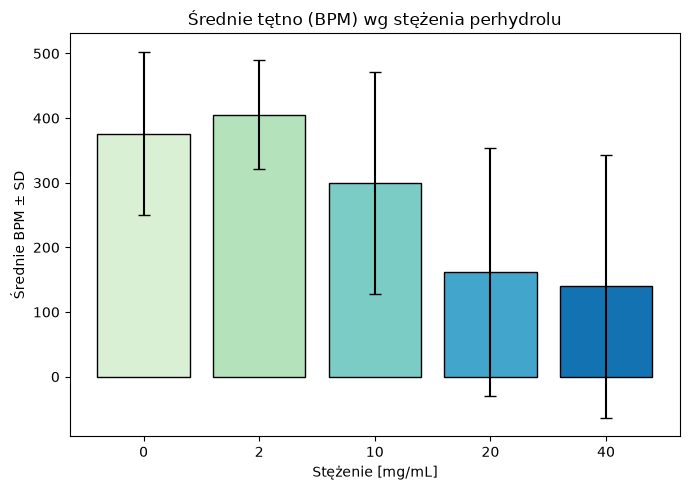

In [45]:
opisowe = df.groupby("Concentration")["BPM"].agg(["mean", "std", "count"]).round(2)

fig, ax = plt.subplots(figsize=(7, 5))
x = np.arange(len(opisowe))
ax.bar(x, opisowe["mean"], yerr=opisowe["std"], capsize=4,
       color=[gnbu_map[c] for c in opisowe.index], edgecolor="black")
ax.set_xticks(x)
ax.set_xticklabels([f"{c:g}" for c in opisowe.index])
ax.set_xlabel("Stężenie [mg/mL]")
ax.set_ylabel("Średnie BPM ± SD")
ax.set_title("Średnie tętno (BPM) wg stężenia perhydrolu")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "01_srednie_bpm_wg_stezenia.png", dpi=300, bbox_inches="tight")
plt.show()

In [7]:
print("Srednie BPM wg stezenia i czasu:")
srednie_tab = df.groupby(["Concentration", "Time"])["BPM"].mean().unstack().round(1)
display(srednie_tab)

Srednie BPM wg stezenia i czasu:


Time,0,2,4,6,8,10,12
Concentration,,,,,,,
0,461.0,415.0,383.0,362.0,370.0,324.0,318.0
2,449.0,448.0,437.0,415.0,372.0,368.0,349.0
10,449.0,420.0,398.0,345.0,242.0,142.0,104.0
20,382.0,357.0,273.0,108.0,17.0,0.0,0.0
40,465.0,431.0,82.0,0.0,0.0,0.0,0.0


In [8]:
print("Odsetek martwych osobnikow (tetno = 0) wg stezenia:")
display((df.groupby("Concentration")["Dead"].mean() * 100).round(1))

Odsetek martwych osobnikow (tetno = 0) wg stezenia:


Concentration
0      6.0
2      0.0
10    19.0
20    52.4
40    64.3
Name: Dead, dtype: float64

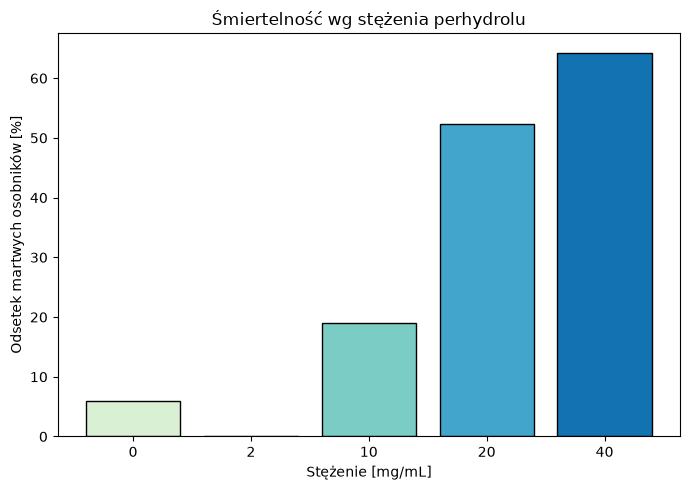

In [47]:
smiertelnosc = (df.groupby("Concentration")["Dead"].mean() * 100).round(1)

fig, ax = plt.subplots(figsize=(7, 5))
ax.bar([f"{c:g}" for c in smiertelnosc.index], smiertelnosc.values,
       color=[gnbu_map[c] for c in smiertelnosc.index], edgecolor="black")
ax.set_xlabel("Stężenie [mg/mL]")
ax.set_ylabel("Odsetek martwych osobników [%]")
ax.set_title("Śmiertelność wg stężenia perhydrolu")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "03_smiertelnosc_wg_stezenia.png", dpi=300, bbox_inches="tight")
plt.show()


### Test chi-kwadrat niezależności: śmiertelność a stężenie

Sprawdza, czy status osobnika (żywy/martwy) jest niezależny od stężenia perhydrolu.


Tabela kontyngencji (żywe/martwe wg stężenia):


,Żywe,Martwe
Concentration,,
0,79,5
2,84,0
10,68,16
20,40,44
40,30,54



Chi-kwadrat: chi2=134.892, df=4, p=3.5e-28  -> zaleznosc istotna statystycznie


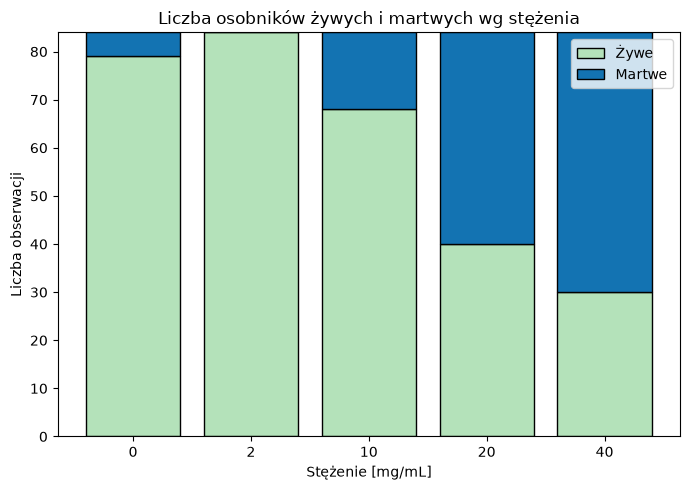

In [49]:
kontyngencja = pd.crosstab(df["Concentration"], df["Dead"])
kontyngencja.columns = ["Żywe", "Martwe"] if False in kontyngencja.columns else kontyngencja.columns
print("Tabela kontyngencji (żywe/martwe wg stężenia):")
display(kontyngencja)

chi2, p_chi2, dof, expected = stats.chi2_contingency(kontyngencja)
flag = "istotna statystycznie" if p_chi2 < ALPHA else "nieistotna statystycznie"
print(f"\nChi-kwadrat: chi2={chi2:.3f}, df={dof}, p={p_chi2:.4g}  -> zaleznosc {flag}")

fig, ax = plt.subplots(figsize=(7, 5))
zywe = kontyngencja.iloc[:, 0]
martwe = kontyngencja.iloc[:, 1]
x = np.arange(len(kontyngencja.index))
ax.bar(x, zywe, label="Żywe", color=gnbu_palette[1], edgecolor="black")
ax.bar(x, martwe, bottom=zywe, label="Martwe", color=gnbu_palette[-1], edgecolor="black")
ax.set_xticks(x)
ax.set_xticklabels([f"{c:g}" for c in kontyngencja.index])
ax.set_xlabel("Stężenie [mg/mL]")
ax.set_ylabel("Liczba obserwacji")
ax.set_title("Liczba osobników żywych i martwych wg stężenia")
ax.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "04_chi2_zywe_martwe.png", dpi=300, bbox_inches="tight")
plt.show()

### Wykres: srednie BPM w czasie, dla kazdego stezenia

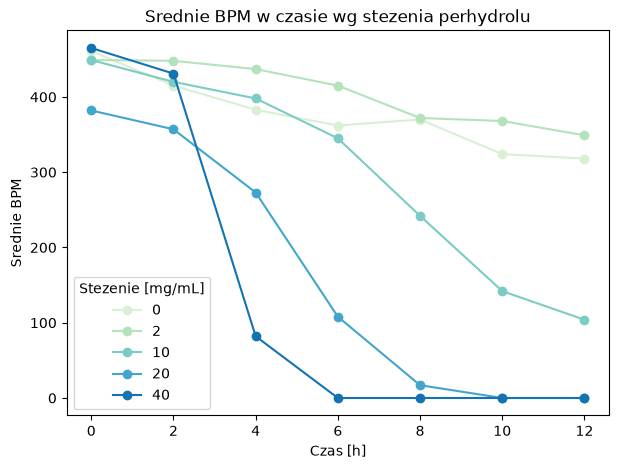

In [48]:
fig, ax = plt.subplots(figsize=(7, 5))
for conc, sub in srednie_tab.iterrows():
    ax.plot(sub.index, sub.values, marker="o", color=gnbu_map[conc], label=f"{conc:g}")
ax.set_xlabel("Czas [h]")
ax.set_ylabel("Srednie BPM")
ax.set_title("Srednie BPM w czasie wg stezenia perhydrolu")
ax.legend(title="Stezenie [mg/mL]")
plt.savefig(OUTPUT_DIR / "02_bpm_w_czasie_wg_stezenia.png", dpi=300, bbox_inches="tight")
plt.show()

## 3. Zalozenia: normalnosc (Shapiro-Wilk) i jednorodnosc wariancji (Levene)

In [12]:
print("Shapiro-Wilk: normalnosc BPM w kazdej grupie stezenia")
groups = []
for conc, sub in df.groupby("Concentration"):
    w, p = stats.shapiro(sub["BPM"])
    groups.append(sub["BPM"].values)
    flag = "OK (normalny)" if p > ALPHA else "ODRZUCONY (nie normalny)"
    print(f"  stezenie {conc:>3}: W={w:.3f}, p={p:.4f}  -> {flag}")

print("\nLevene: jednorodnosc wariancji miedzy grupami stezen")
stat, p = stats.levene(*groups)
flag = "OK (wariancje rowne)" if p > ALPHA else "ODRZUCONA (wariancje rozne)"
print(f"  Levene stat={stat:.3f}, p={p:.4f}  -> {flag}")

Shapiro-Wilk: normalnosc BPM w kazdej grupie stezenia
  stezenie   0: W=0.818, p=0.0000  -> ODRZUCONY (nie normalny)
  stezenie   2: W=0.892, p=0.0000  -> ODRZUCONY (nie normalny)
  stezenie  10: W=0.828, p=0.0000  -> ODRZUCONY (nie normalny)
  stezenie  20: W=0.743, p=0.0000  -> ODRZUCONY (nie normalny)
  stezenie  40: W=0.672, p=0.0000  -> ODRZUCONY (nie normalny)

Levene: jednorodnosc wariancji miedzy grupami stezen
  Levene stat=6.896, p=0.0000  -> ODRZUCONA (wariancje rozne)


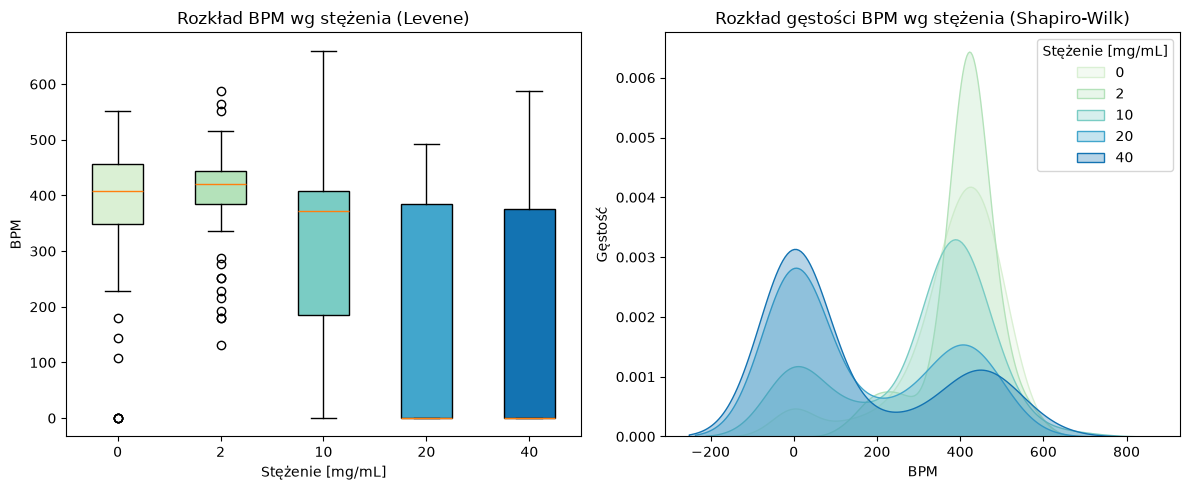

In [50]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

dane_wg_stez = [df[df.Concentration == c]["BPM"].values for c in concentrations_sorted]
bp = axes[0].boxplot(dane_wg_stez, patch_artist=True,
                     tick_labels=[f"{c:g}" for c in concentrations_sorted])
for patch, c in zip(bp["boxes"], concentrations_sorted):
    patch.set_facecolor(gnbu_map[c])
axes[0].set_xlabel("Stężenie [mg/mL]")
axes[0].set_ylabel("BPM")
axes[0].set_title("Rozkład BPM wg stężenia (Levene)")

for c in concentrations_sorted:
    sns.kdeplot(df[df.Concentration == c]["BPM"], ax=axes[1], color=gnbu_map[c],
                label=f"{c:g}", fill=True, alpha=0.3)
axes[1].set_xlabel("BPM")
axes[1].set_ylabel("Gęstość")
axes[1].set_title("Rozkład gęstości BPM wg stężenia (Shapiro-Wilk)")
axes[1].legend(title="Stężenie [mg/mL]")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "05_zalozenia_boxplot_kde.png", dpi=300, bbox_inches="tight")
plt.show()


Jesli powyzsze zalozenia sa odrzucone (jak w tych danych), klasyczna ANOVA jest tylko pomocnicza - glowny wniosek lepiej oprzec na wersjach nieparametrycznych ponizej.

## 4. Wielkosc efektu - Cohen's d (kazde stezenie vs kontrola)

In [14]:
def cohens_d(x, y):
    nx, ny = len(x), len(y)
    pooled_sd = np.sqrt(((nx - 1) * np.var(x, ddof=1) + (ny - 1) * np.var(y, ddof=1)) / (nx + ny - 2))
    return (np.mean(x) - np.mean(y)) / pooled_sd

control = df[df.Concentration == 0]["BPM"].values
for conc in sorted(df.Concentration.unique()):
    if conc == 0:
        continue
    grp = df[df.Concentration == conc]["BPM"].values
    d = cohens_d(grp, control)
    mag = "mala" if abs(d) < 0.5 else "srednia" if abs(d) < 0.8 else "duza"
    print(f"  stezenie {conc:>3}: d = {d:.3f}  ({mag})")

  stezenie   2: d = 0.272  (mala)
  stezenie  10: d = -0.505  (srednia)
  stezenie  20: d = -1.315  (duza)
  stezenie  40: d = -1.393  (duza)


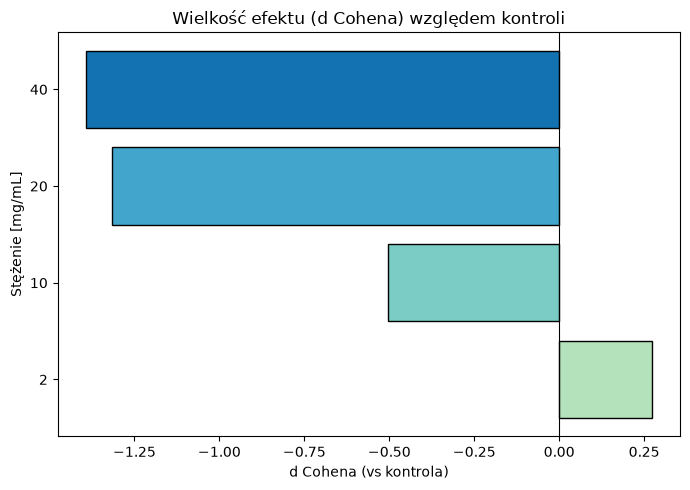

In [51]:
d_values, d_concs = [], []
for conc in concentrations_sorted:
    if conc == 0:
        continue
    grp = df[df.Concentration == conc]["BPM"].values
    d_values.append(cohens_d(grp, control))
    d_concs.append(conc)

fig, ax = plt.subplots(figsize=(7, 5))
ax.barh([f"{c:g}" for c in d_concs], d_values,
        color=[gnbu_map[c] for c in d_concs], edgecolor="black")
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("d Cohena (vs kontrola)")
ax.set_ylabel("Stężenie [mg/mL]")
ax.set_title("Wielkość efektu (d Cohena) względem kontroli")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "06_cohens_d.png", dpi=300, bbox_inches="tight")
plt.show()


## 5. Dwuczynnikowa ANOVA (Stezenie x Czas)

Liczona recznie (dziala bez `statsmodels`; jesli masz `statsmodels`, mozesz zastapic to `ols(...).fit()` + `anova_lm`, wynik bedzie identyczny dla zbalansowanego ukladu).

In [16]:
def two_way_anova(data, dv, factor_a, factor_b):
    grand_mean = data[dv].mean()
    N = len(data)
    a_levels = data[factor_a].unique()
    b_levels = data[factor_b].unique()
    cell_counts = data.groupby([factor_a, factor_b]).size()

    ss_total = ((data[dv] - grand_mean) ** 2).sum()

    means_a = data.groupby(factor_a)[dv].mean()
    n_a = data.groupby(factor_a).size()
    ss_a = (n_a * (means_a - grand_mean) ** 2).sum()

    means_b = data.groupby(factor_b)[dv].mean()
    n_b = data.groupby(factor_b).size()
    ss_b = (n_b * (means_b - grand_mean) ** 2).sum()

    means_cell = data.groupby([factor_a, factor_b])[dv].mean()
    ss_cells = (cell_counts * (means_cell - grand_mean) ** 2).sum()
    ss_ab = ss_cells - ss_a - ss_b
    ss_error = ss_total - ss_cells

    df_a, df_b = len(a_levels) - 1, len(b_levels) - 1
    df_ab = df_a * df_b
    df_error = N - len(a_levels) * len(b_levels)

    ms_a, ms_b, ms_ab, ms_error = ss_a/df_a, ss_b/df_b, ss_ab/df_ab, ss_error/df_error
    f_a, f_b, f_ab = ms_a/ms_error, ms_b/ms_error, ms_ab/ms_error
    p_a = stats.f.sf(f_a, df_a, df_error)
    p_b = stats.f.sf(f_b, df_b, df_error)
    p_ab = stats.f.sf(f_ab, df_ab, df_error)

    return pd.DataFrame({
        "SS": [ss_a, ss_b, ss_ab, ss_error],
        "df": [df_a, df_b, df_ab, df_error],
        "F": [f_a, f_b, f_ab, np.nan],
        "p": [p_a, p_b, p_ab, np.nan],
    }, index=[factor_a, factor_b, f"{factor_a}:{factor_b}", "residual"])

print("ANOVA na surowych BPM:")
display(two_way_anova(df, "BPM", "Concentration", "Time").round(4))

ANOVA na surowych BPM:


,SS,df,F,p
Concentration,4.941372e+06,4,124.6216,0.0
Time,4.876914e+06,6,81.9973,0.0
Concentration:Time,2.176851e+06,24,9.1500,0.0
residual,3.816408e+06,385,NaN,NaN


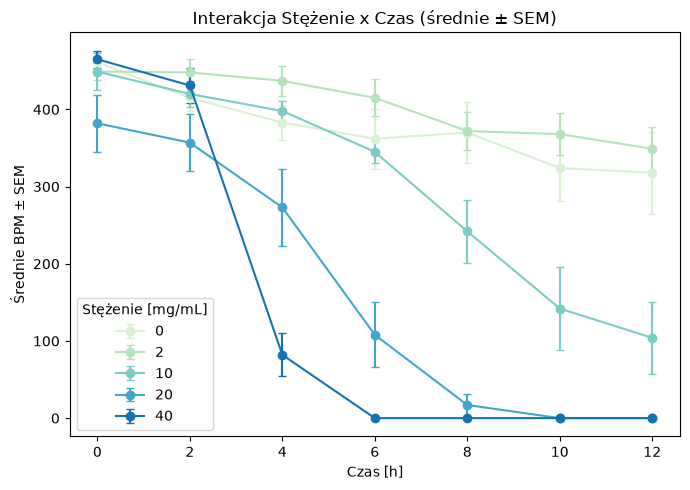

In [52]:
agg_sem = df.groupby(["Concentration", "Time"])["BPM"].agg(["mean", "sem"]).reset_index()

fig, ax = plt.subplots(figsize=(7, 5))
for conc in concentrations_sorted:
    sub = agg_sem[agg_sem.Concentration == conc]
    ax.errorbar(sub["Time"], sub["mean"], yerr=sub["sem"], marker="o", capsize=3,
                color=gnbu_map[conc], label=f"{conc:g}")
ax.set_xlabel("Czas [h]")
ax.set_ylabel("Średnie BPM ± SEM")
ax.set_title("Interakcja Stężenie x Czas (średnie ± SEM)")
ax.legend(title="Stężenie [mg/mL]")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "07_interakcja_stezenie_czas.png", dpi=300, bbox_inches="tight")
plt.show()

### Scheirer-Ray-Hare (nieparametryczny odpowiednik 2-way ANOVA, na rangach)

Zalecane w tym przypadku, bo dane nie sa normalne ani homogeniczne wariancyjnie.

In [18]:
df_ranked = df.copy()
df_ranked["BPM"] = stats.rankdata(df["BPM"])
print("Scheirer-Ray-Hare (ANOVA na rangach):")
display(two_way_anova(df_ranked, "BPM", "Concentration", "Time").round(4))

Scheirer-Ray-Hare (ANOVA na rangach):


,SS,df,F,p
Concentration,1.494306e+06,4,72.8600,0.0
Time,1.978545e+06,6,64.3138,0.0
Concentration:Time,5.789912e+05,24,4.7051,0.0
residual,1.974017e+06,385,NaN,NaN


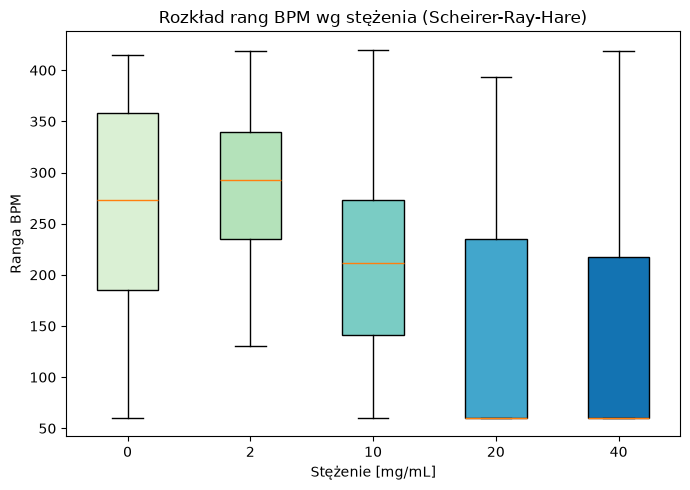

In [54]:
fig, ax = plt.subplots(figsize=(7, 5))
dane_rang = [df_ranked[df_ranked.Concentration == c]["BPM"].values for c in concentrations_sorted]
bp = ax.boxplot(dane_rang, patch_artist=True,
                tick_labels=[f"{c:g}" for c in concentrations_sorted])
for patch, c in zip(bp["boxes"], concentrations_sorted):
    patch.set_facecolor(gnbu_map[c])
ax.set_xlabel("Stężenie [mg/mL]")
ax.set_ylabel("Ranga BPM")
ax.set_title("Rozkład rang BPM wg stężenia (Scheirer-Ray-Hare)")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "08_scheirer_ray_hare_rangi.png", dpi=300, bbox_inches="tight")
plt.show()

## 6. Post-hoc: Kruskal-Wallis + Tukey HSD wg stezenia

In [20]:
groups = [g["BPM"].values for _, g in df.groupby("Concentration")]
labels = sorted(df.Concentration.unique())

h, p = stats.kruskal(*groups)
print(f"Kruskal-Wallis: H={h:.3f}, p={p:.4g}")

print(f"\nTukey HSD (kolejnosc grup: {labels}):")
res = stats.tukey_hsd(*groups)
print(res)

Kruskal-Wallis: H=103.905, p=1.45e-21

Tukey HSD (kolejnosc grup: [np.int64(0), np.int64(2), np.int64(10), np.int64(20), np.int64(40)]):
Pairwise Group Comparisons (95.0% Confidence Interval)
Comparison  Statistic  p-value  Lower CI  Upper CI
 (0 - 1)    -29.286     0.767   -97.707    39.135
 (0 - 2)     76.143     0.021     7.722   144.564
 (0 - 3)    213.714     0.000   145.293   282.135
 (0 - 4)    236.429     0.000   168.007   304.850
 (1 - 0)     29.286     0.767   -39.135    97.707
 (1 - 2)    105.429     0.000    37.007   173.850
 (1 - 3)    243.000     0.000   174.579   311.421
 (1 - 4)    265.714     0.000   197.293   334.135
 (2 - 0)    -76.143     0.021  -144.564    -7.722
 (2 - 1)   -105.429     0.000  -173.850   -37.007
 (2 - 3)    137.571     0.000    69.150   205.993
 (2 - 4)    160.286     0.000    91.865   228.707
 (3 - 0)   -213.714     0.000  -282.135  -145.293
 (3 - 1)   -243.000     0.000  -311.421  -174.579
 (3 - 2)   -137.571     0.000  -205.993   -69.150
 (3 - 4

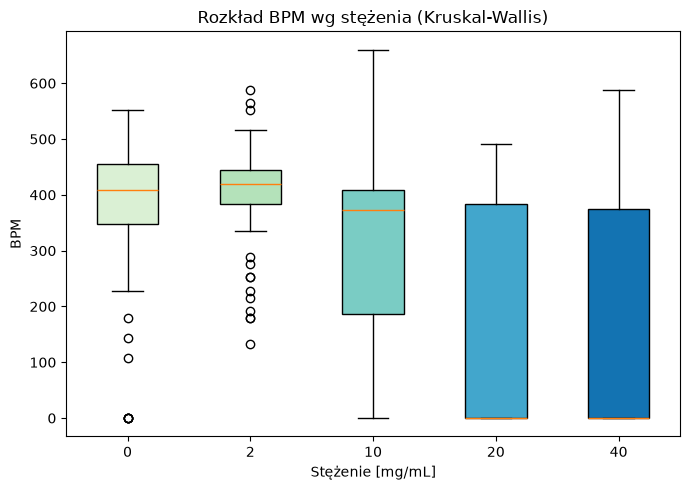

In [55]:
fig, ax = plt.subplots(figsize=(7, 5))
bp = ax.boxplot(groups, patch_artist=True, tick_labels=[f"{c:g}" for c in labels])
for patch, c in zip(bp["boxes"], labels):
    patch.set_facecolor(gnbu_map[c])
ax.set_xlabel("Stężenie [mg/mL]")
ax.set_ylabel("BPM")
ax.set_title("Rozkład BPM wg stężenia (Kruskal-Wallis)")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "09_kruskal_wallis_boxplot.png", dpi=300, bbox_inches="tight")
plt.show()


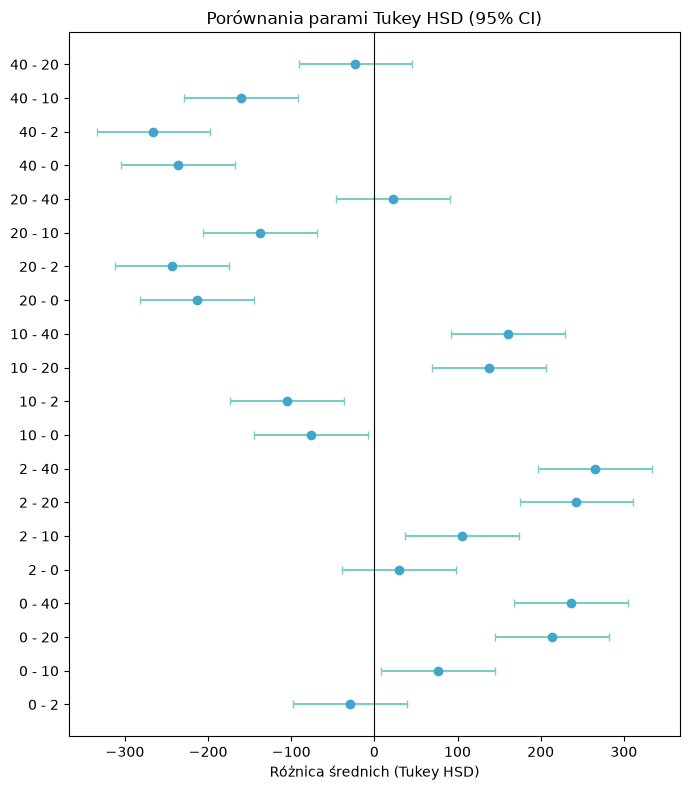

In [56]:
n_grp = len(labels)
porownania, staty, ci_lo, ci_hi = [], [], [], []
ci = res.confidence_interval()
for a in range(n_grp):
    for b in range(n_grp):
        if a == b:
            continue
        porownania.append(f"{labels[a]:g} - {labels[b]:g}")
        staty.append(res.statistic[a, b])
        ci_lo.append(ci.low[a, b])
        ci_hi.append(ci.high[a, b])

fig, ax = plt.subplots(figsize=(7, 8))
y_pos = np.arange(len(porownania))
bledy = [np.array(staty) - np.array(ci_lo), np.array(ci_hi) - np.array(staty)]
ax.errorbar(staty, y_pos, xerr=bledy, fmt="o", color=gnbu_palette[-2],
            ecolor=gnbu_palette[2], capsize=3)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_yticks(y_pos)
ax.set_yticklabels(porownania)
ax.set_xlabel("Różnica średnich (Tukey HSD)")
ax.set_title("Porównania parami Tukey HSD (95% CI)")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "10_tukey_hsd_forest.png", dpi=300, bbox_inches="tight")
plt.show()

## 7. Zapis danych w formacie dlugim (opcjonalnie)

In [23]:
df.to_csv("dane_long_format.csv", index=False)
print("Zapisano do dane_long_format.csv")

Zapisano do dane_long_format.csv


#### Analiza dla automatycznego przeliczania tempa

In [ ]:
# Srednie BPM wg stezenia i czasu - srednia z wynikow (heart_rate_comparison.csv) z 3 folderow
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

BASE_OUTPUT_DIR = Path("/home/marcelina/D.magna/Krótki")
REPLICATE_NAMES = ["20250909", "20250910", "20250911"]

frames = []
for rep_name in REPLICATE_NAMES:
    rep_path = BASE_OUTPUT_DIR / rep_name / "heart_rate_comparison.csv"
    if not rep_path.exists():
        raise FileNotFoundError(f"Brak pliku dla powtórzenia {rep_name}: {rep_path}")
    frames.append(pd.read_csv(rep_path))

combined_df = pd.concat(frames, ignore_index=True)

# BPM z automatycznej metody jasnosci ROI (kolumna auto_jasnosc_hz -> BPM)
combined_df["bpm"] = combined_df["auto_jasnosc_hz"] * 60
combined_df = combined_df.dropna(subset=["bpm", "stężenie_mg", "punkt_czasowy_h"])

print(f"Polaczono {len(REPLICATE_NAMES)} powtorzen, lacznie {len(combined_df)} nagran.")

# Srednie BPM wg stezenia (po zsumowaniu czasu)
srednie_bpm_stezenie = combined_df.groupby("stężenie_mg")["bpm"].agg(["mean", "std", "count"]).round(2)
print("\nSrednie BPM wg stezenia:")
display(srednie_bpm_stezenie)

# Srednie BPM wg stezenia i czasu
srednie_bpm_czas = (
    combined_df.groupby(["stężenie_mg", "punkt_czasowy_h"])["bpm"]
    .mean()
    .unstack()
    .round(1)
)
print("\nSrednie BPM wg stezenia i czasu:")
display(srednie_bpm_czas)

# Wykres: srednie BPM w czasie, dla kazdego stezenia
fig, ax = plt.subplots(figsize=(9, 6))
for concentration, row in srednie_bpm_czas.iterrows():
    ax.plot(row.index, row.values, marker="o", label=f"{concentration:g} mg")
ax.set_xlabel("Czas [h]")
ax.set_ylabel("Średnie BPM (z 3 powtórzeń)")
ax.set_title("Średnie BPM w czasie, dla każdego stężenia (3 powtórzenia)")
ax.legend(title="Stężenie")
plt.tight_layout()

fig.savefig(BASE_OUTPUT_DIR / "srednie_bpm_3_powtorzenia.png", dpi=300, bbox_inches="tight")
plt.show()

FileNotFoundError: Brak pliku dla powtórzenia 20250909: /home/marcelina/D.magna/Krótki/20250909/heart_rate_results_checkpoint.csv